# Global Health Statistics: Data Cleaning & Exploratory Data Analysis
**ICA Group Project, IBA Karachi**
Team: Lamiah Sahar, Aliya Fatima, Amna Iqbal, Faryal Zia

**Dataset:** Global Health Statistics (22 attributes: disease prevalence, incidence, mortality, healthcare access, demographics, treatment and socioeconomic indicators).

**Goal:** Clean the data, explore it with pandas/NumPy/Matplotlib/Seaborn, and examine how healthcare access and socioeconomic factors relate to mortality and recovery.

**Notebook outline**
1. Setup and loading
2. Data cleaning (types, missing values)
3. Univariate analysis (numerical and categorical)
4. Trend analysis
5. Bivariate analysis (pivot table, correlations, scatter plots)
6. Key findings and limitations

## 1. Setup and loading

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import normaltest, skew

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv("Global Health Statistics.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (80277, 22)


,Country,Year,Disease Name,Disease Category,Prevalence Rate (%),Incidence Rate (%),Mortality Rate (%),Age Group,Gender,Population Affected,Healthcare Access (%),Doctors per 1000,Hospital Beds per 1000,Treatment Type,Average Treatment Cost (USD),Availability of Vaccines/Treatment,Recovery Rate (%),DALYs,Improvement in 5 Years (%),Per Capita Income (USD),Education Index,Urbanization Rate (%)
0,Saudi Arabia,2023.0,Hypertension,Metabolic,14.72,13.90,3.28,36-60,Female,28737.0,97.73,4.51,5.60,Medication,24176.0,No,85.19,783.0,3.90,8158.0,0.61,76.37
1,Russia,2023.0,Leprosy,Bacterial,16.22,8.43,9.61,61+,Other,422327.0,51.80,3.75,2.98,Therapy,27605.0,Yes,98.03,3145.0,4.23,13691.0,0.79,22.94
2,UK,2023.0,Polio,Bacterial,10.69,5.69,3.12,19-35,Male,55467.0,53.02,3.58,2.32,Vaccination,10052.0,No,71.01,959.0,5.57,87935.0,0.64,89.02
3,South Korea,2023.0,Ebola,Chronic,9.74,11.62,3.87,0-18,Male,15852.0,91.80,2.92,8.71,Vaccination,33473.0,Yes,76.67,3585.0,3.33,33284.0,0.53,47.29
4,China,2023.0,Cancer,Genetic,18.82,1.97,0.55,19-35,Male,421832.0,87.89,1.42,3.33,Vaccination,49084.0,Yes,83.95,2231.0,1.40,49305.0,0.65,30.79


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 80277 entries, 0 to 80276
Data columns (total 22 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Country                             80264 non-null  str    
 1   Year                                80252 non-null  float64
 2   Disease Name                        80262 non-null  str    
 3   Disease Category                    80257 non-null  str    
 4   Prevalence Rate (%)                 80257 non-null  float64
 5   Incidence Rate (%)                  80257 non-null  float64
 6   Mortality Rate (%)                  80265 non-null  float64
 7   Age Group                           80257 non-null  str    
 8   Gender                              80257 non-null  str    
 9   Population Affected                 80198 non-null  float64
 10  Healthcare Access (%)               80238 non-null  float64
 11  Doctors per 1000                    80238 non-null  

## 2. Data cleaning
### 2.1 Missing values (before cleaning)

In [4]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Total missing cells:", df.isnull().sum().sum())
missing.to_frame("missing_count").assign(missing_pct=lambda x: (x.missing_count / len(df) * 100).round(3))

Total missing cells: 696


,missing_count,missing_pct
Population Affected,79,0.098
Average Treatment Cost (USD),47,0.059
Urbanization Rate (%),47,0.059
Education Index,47,0.059
Per Capita Income (USD),47,0.059
Improvement in 5 Years (%),47,0.059
Doctors per 1000,39,0.049
Healthcare Access (%),39,0.049
Availability of Vaccines/Treatment,35,0.044
DALYs,35,0.044


### 2.2 Handling missing values
Strategy:
- **Categorical columns:** fill with the mode (most frequent value).
- **Rate / index columns** (prevalence, incidence, mortality, recovery, healthcare access, etc.): fill with the **mean**.
- **Count / cost / income columns** (population affected, treatment cost, DALYs, income): fill with the **median**, which is less affected by extreme values.
- **Year:** fill with the mode, since it is a discrete label.

We work on a copy so the raw data stays available for comparison.

In [5]:
clean = df.copy()

categorical_cols = clean.select_dtypes(exclude="number").columns.tolist()
year_col = ["Year"]
median_cols = ["Population Affected", "Average Treatment Cost (USD)", "DALYs", "Per Capita Income (USD)"]
mean_cols = [c for c in clean.select_dtypes(include="number").columns
             if c not in median_cols + year_col]

for c in categorical_cols + year_col:
    clean[c] = clean[c].fillna(clean[c].mode()[0])
for c in mean_cols:
    clean[c] = clean[c].fillna(clean[c].mean())
for c in median_cols:
    clean[c] = clean[c].fillna(clean[c].median())

print("Mean-imputed:", mean_cols)
print("Median-imputed:", median_cols)
print("Mode-imputed:", categorical_cols + year_col)
print("\nRemaining missing values:", clean.isnull().sum().sum())

Mean-imputed: ['Prevalence Rate (%)', 'Incidence Rate (%)', 'Mortality Rate (%)', 'Healthcare Access (%)', 'Doctors per 1000', 'Hospital Beds per 1000', 'Recovery Rate (%)', 'Improvement in 5 Years (%)', 'Education Index', 'Urbanization Rate (%)']
Median-imputed: ['Population Affected', 'Average Treatment Cost (USD)', 'DALYs', 'Per Capita Income (USD)']
Mode-imputed: ['Country', 'Disease Name', 'Disease Category', 'Age Group', 'Gender', 'Treatment Type', 'Availability of Vaccines/Treatment', 'Year']



Remaining missing values: 0


### 2.3 Fixing data types
`Year`, `Population Affected`, `Average Treatment Cost (USD)`, `DALYs` and `Per Capita Income (USD)` represent whole numbers, so they are converted to integers (after imputation, because integer columns cannot hold NaN).

In [6]:
int_cols = ["Year", "Population Affected", "Average Treatment Cost (USD)", "DALYs", "Per Capita Income (USD)"]
clean[int_cols] = clean[int_cols].round().astype("int64")

df = clean   # use the cleaned data from here on
print(df.dtypes)
print("\nDuplicate rows:", df.duplicated().sum())

Country                                   str
Year                                    int64
Disease Name                              str
Disease Category                          str
Prevalence Rate (%)                   float64
Incidence Rate (%)                    float64
Mortality Rate (%)                    float64
Age Group                                 str
Gender                                    str
Population Affected                     int64
Healthcare Access (%)                 float64
Doctors per 1000                      float64
Hospital Beds per 1000                float64
Treatment Type                            str
Average Treatment Cost (USD)            int64
Availability of Vaccines/Treatment        str
Recovery Rate (%)                     float64
DALYs                                   int64
Improvement in 5 Years (%)            float64
Per Capita Income (USD)                 int64
Education Index                       float64
Urbanization Rate (%)             


Duplicate rows: 0


## 3. Univariate analysis
### 3.1 Descriptive statistics

In [7]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Year,80277.0,2023.498,0.500,2023.0,2023.00,2023.00,2024.00,2024.0
Prevalence Rate (%),80277.0,10.034,5.742,0.1,5.09,10.02,15.02,20.0
Incidence Rate (%),80277.0,7.551,4.294,0.1,3.84,7.56,11.26,15.0
Mortality Rate (%),80277.0,5.047,2.861,0.1,2.58,5.04,7.53,10.0
Population Affected,80277.0,500855.883,288237.922,1011.0,251123.00,501163.00,750651.00,999998.0
Healthcare Access (%),80277.0,75.005,14.464,50.0,62.37,75.07,87.54,100.0
Doctors per 1000,80277.0,2.751,1.301,0.5,1.62,2.75,3.88,5.0
Hospital Beds per 1000,80277.0,5.242,2.748,0.5,2.86,5.24,7.62,10.0
Average Treatment Cost (USD),80277.0,25045.913,14398.744,100.0,12569.00,25096.00,37537.00,50000.0
Recovery Rate (%),80277.0,74.540,14.181,50.0,62.27,74.53,86.89,99.0


In [8]:
print("Years in the data:", sorted(df["Year"].unique().tolist()))
print("Countries:", df["Country"].nunique(), "| Diseases:", df["Disease Name"].nunique())

Years in the data: [2023, 2024]
Countries: 20 | Diseases: 20


### 3.2 Numerical variables: boxplots, distributions and normality
With a very large sample, `normaltest` will almost always reject normality (even for tiny deviations), so we also report **skewness** and look at the histograms rather than relying on the p-value alone.

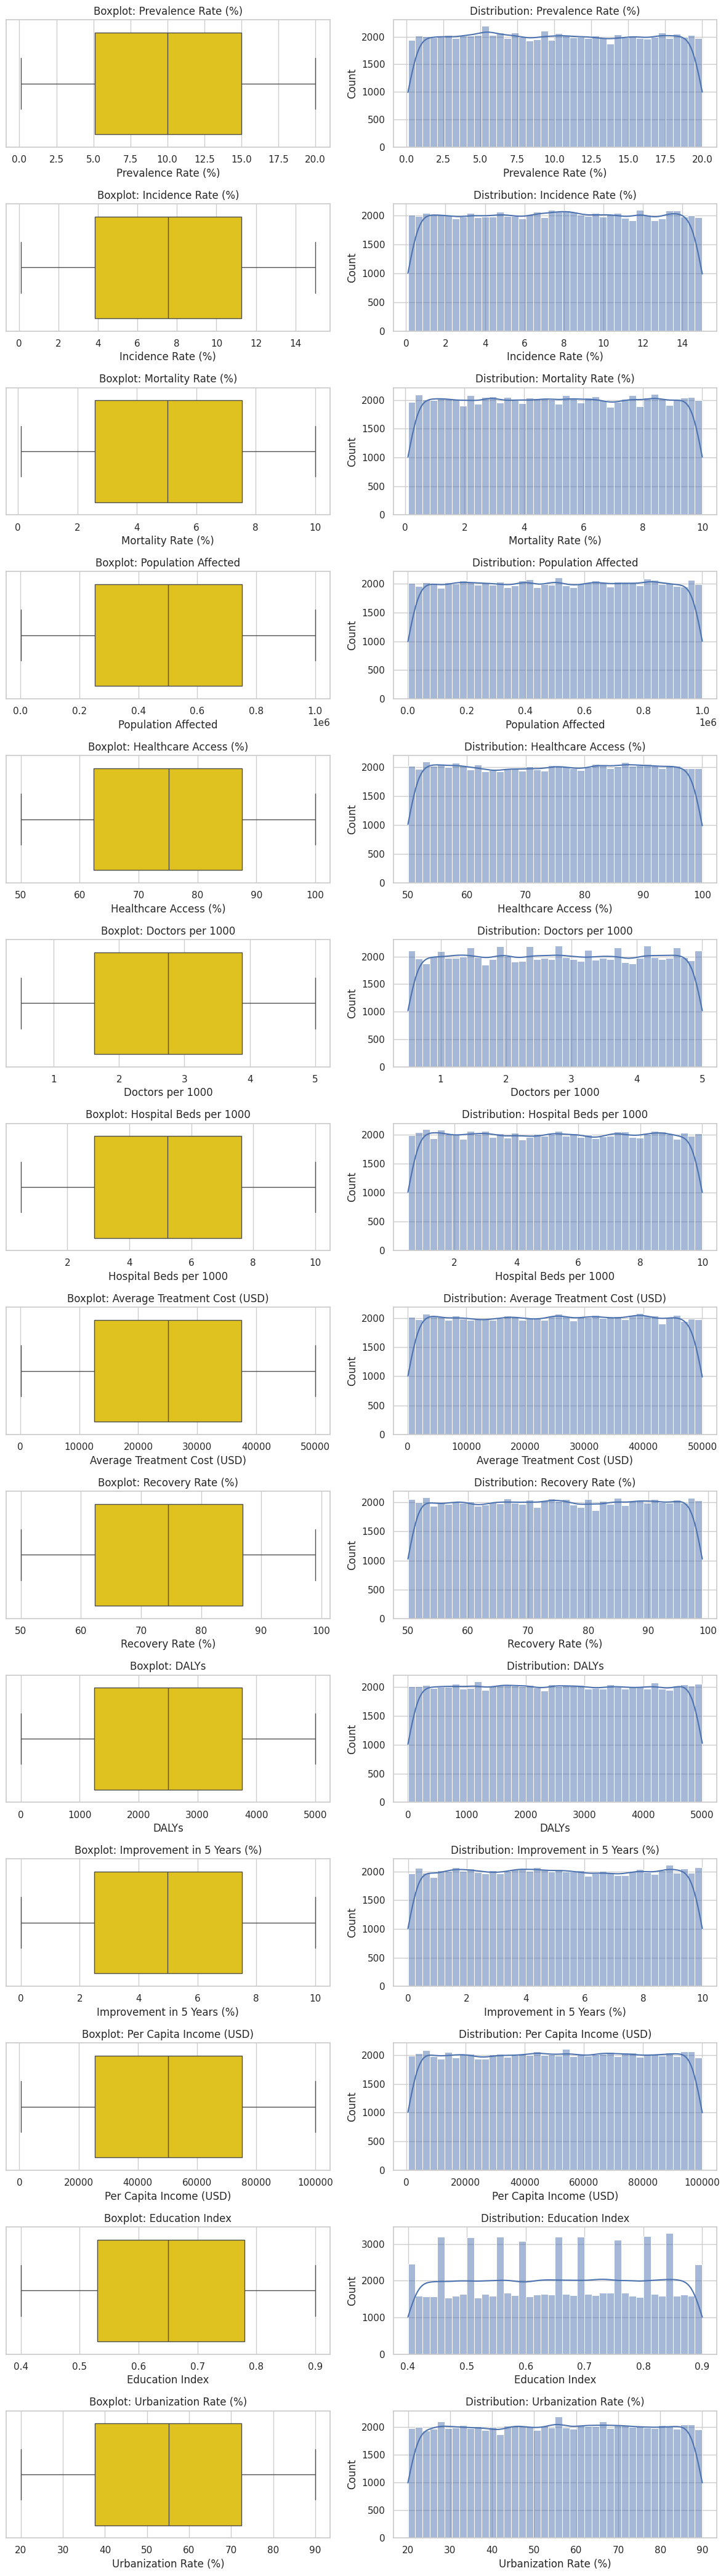

In [9]:
num_cols = df.select_dtypes(include="number").columns.drop("Year")

fig, axes = plt.subplots(len(num_cols), 2, figsize=(12, 3 * len(num_cols)))
for i, col in enumerate(num_cols):
    sns.boxplot(x=df[col], ax=axes[i, 0], color="gold")
    axes[i, 0].set_title(f"Boxplot: {col}")
    sns.histplot(df[col], bins=40, kde=True, ax=axes[i, 1])
    axes[i, 1].set_title(f"Distribution: {col}")
plt.tight_layout()
plt.show()

In [10]:
rows = []
for col in num_cols:
    stat, p = normaltest(df[col])
    rows.append({"column": col, "skewness": round(skew(df[col]), 4),
                 "normaltest_p": round(p, 4), "looks_normal": p > 0.05})
pd.DataFrame(rows)

,column,skewness,normaltest_p,looks_normal
0,Prevalence Rate (%),0.0095,0.0,False
1,Incidence Rate (%),-0.0021,0.0,False
2,Mortality Rate (%),0.0018,0.0,False
3,Population Affected,-0.0018,0.0,False
4,Healthcare Access (%),-0.0082,0.0,False
5,Doctors per 1000,0.0005,0.0,False
6,Hospital Beds per 1000,0.0020,0.0,False
7,Average Treatment Cost (USD),-0.0047,0.0,False
8,Recovery Rate (%),-0.0038,0.0,False
9,DALYs,0.0035,0.0,False


### 3.3 Categorical variables

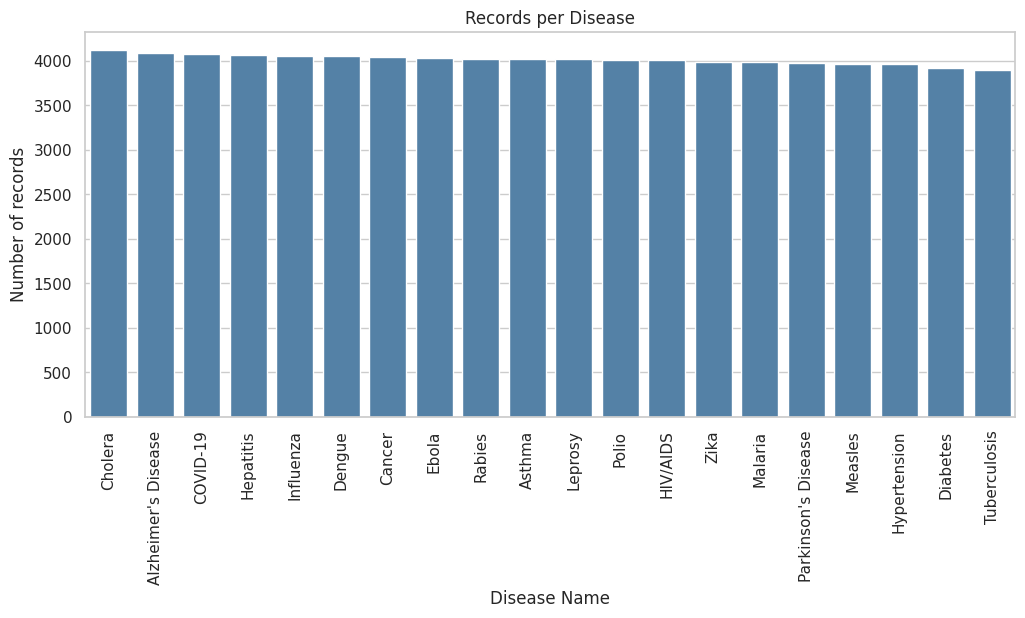

Most records: Cholera (4116), fewest: Tuberculosis (3893)
Gap between most and fewest is only 5.6% of the average, so the diseases are almost evenly represented.


In [11]:
disease_counts = df["Disease Name"].value_counts()
plt.figure(figsize=(12, 5))
sns.barplot(x=disease_counts.index, y=disease_counts.values, color="steelblue")
plt.xticks(rotation=90)
plt.ylabel("Number of records")
plt.title("Records per Disease")
plt.show()

spread = (disease_counts.max() - disease_counts.min()) / disease_counts.mean() * 100
print(f"Most records: {disease_counts.idxmax()} ({disease_counts.max()}), fewest: {disease_counts.idxmin()} ({disease_counts.min()})")
print(f"Gap between most and fewest is only {spread:.1f}% of the average, so the diseases are almost evenly represented.")

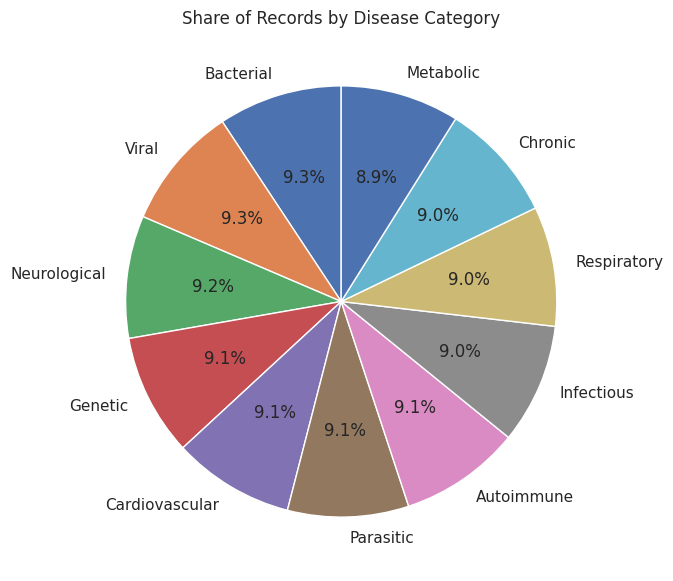

Largest vs smallest share: 9.3 % vs 8.91 %


In [12]:
cat_share = df["Disease Category"].value_counts(normalize=True) * 100
plt.figure(figsize=(7, 7))
plt.pie(cat_share, labels=cat_share.index, autopct="%1.1f%%", startangle=90)
plt.title("Share of Records by Disease Category")
plt.show()
print("Largest vs smallest share:", round(cat_share.max(), 2), "% vs", round(cat_share.min(), 2), "%")

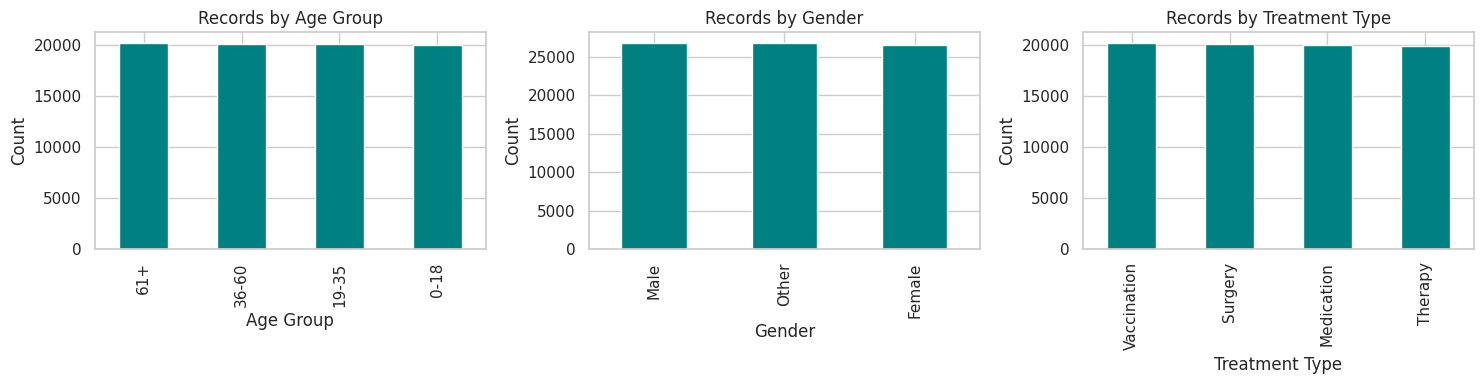

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Age Group", "Gender", "Treatment Type"]):
    df[col].value_counts().plot(kind="bar", ax=ax, color="teal")
    ax.set_title(f"Records by {col}")
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

## 4. Trend analysis
The dataset contains **only two years (2023 and 2024)**, so a "trend" is the change between two points. The charts below start the y-axis at zero so small changes are not exaggerated, and the table reports the exact percentage change.

,first_year,last_year,change_%
Mortality Rate (%),5.043679,5.050198,0.129
Prevalence Rate (%),10.048299,10.019279,-0.289
Healthcare Access (%),75.030754,74.978364,-0.070
Per Capita Income (USD),50294.219844,50371.741244,0.154
Education Index,0.650856,0.650610,-0.038


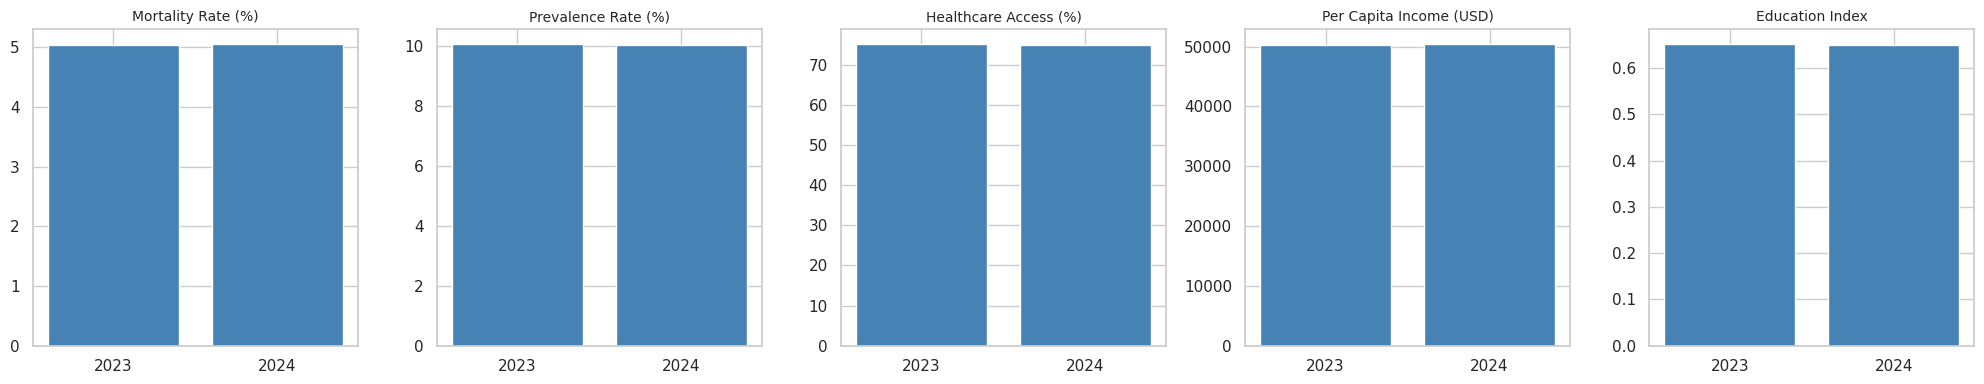

In [14]:
trend_cols = ["Mortality Rate (%)", "Prevalence Rate (%)", "Healthcare Access (%)",
              "Per Capita Income (USD)", "Education Index"]
yearly = df.groupby("Year")[trend_cols].mean()

change = pd.DataFrame({
    "first_year": yearly.iloc[0],
    "last_year": yearly.iloc[-1],
})
change["change_%"] = ((change.last_year - change.first_year) / change.first_year * 100).round(3)
display(change)

fig, axes = plt.subplots(1, len(trend_cols), figsize=(20, 4))
for ax, col in zip(axes, trend_cols):
    ax.bar(yearly.index.astype(str), yearly[col], color="steelblue")
    ax.set_title(col, fontsize=10)
    ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

## 5. Bivariate analysis
### 5.1 Pivot table
We use the **mean** (not the sum) because mortality and recovery are rates in percent. Summing percentages across records is not meaningful. Population Affected is a count, so its sum is valid.

In [15]:
pivot_rates = df.pivot_table(index=["Country", "Year"],
                             values=["Mortality Rate (%)", "Recovery Rate (%)"],
                             aggfunc="mean").round(3)
pivot_pop = df.pivot_table(index=["Country", "Year"], values="Population Affected", aggfunc="sum")
pivot_table = pivot_rates.join(pivot_pop)
pivot_table.head(10)

Mortality Rate (%)  Recovery Rate (%)  Population Affected
Country   Year                                                            
Argentina 2023               5.087             74.468            966934791
          2024               5.054             74.454            991206406
Australia 2023               4.940             74.519           1019013359
          2024               5.019             74.465            995795256
Brazil    2023               5.056             74.766            988892497
          2024               5.152             74.128            990232279
Canada    2023               5.087             74.612           1025801015
          2024               5.112             74.712            976222967
China     2023               4.943             74.707           1081707684
          2024               5.141             74.554           1024421847

In [16]:
top = (df.groupby("Country")[["Mortality Rate (%)", "Recovery Rate (%)"]].mean()
         .sort_values("Mortality Rate (%)", ascending=False).round(3))
print("Highest average mortality rate:")
display(top.head(5))
print("Lowest average mortality rate:")
display(top.tail(5))

Highest average mortality rate:


,Mortality Rate (%),Recovery Rate (%)
Country,,
South Korea,5.106,74.687
Brazil,5.104,74.448
UK,5.101,74.605
Canada,5.099,74.661
Indonesia,5.095,74.708


Lowest average mortality rate:


,Mortality Rate (%),Recovery Rate (%)
Country,,
India,5.010,74.515
Nigeria,5.003,74.634
Italy,4.995,74.777
Australia,4.980,74.492
USA,4.926,74.536


### 5.2 Correlation matrix (numerical features)

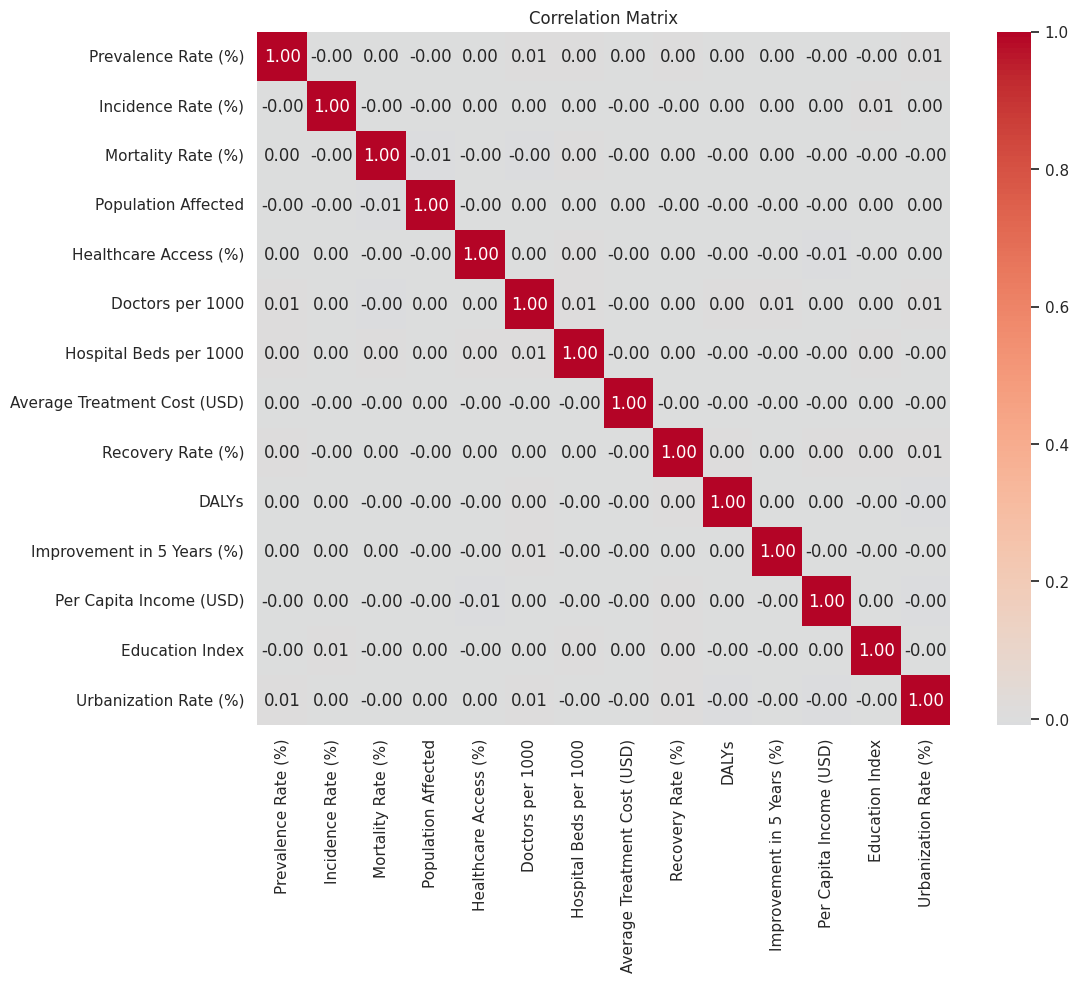

In [17]:
corr = df[num_cols].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Matrix")
plt.show()

In [18]:
for target in ["Mortality Rate (%)", "Recovery Rate (%)"]:
    s = corr[target].drop(target).sort_values(key=abs, ascending=False)
    print(f"Features most correlated with {target}:")
    print(s.head(5).round(3).to_string(), "\n")

Features most correlated with Mortality Rate (%):
Population Affected       -0.008
Doctors per 1000          -0.005
Hospital Beds per 1000     0.004
Per Capita Income (USD)   -0.004
Healthcare Access (%)     -0.003 

Features most correlated with Recovery Rate (%):
Urbanization Rate (%)      0.006
DALYs                      0.004
Per Capita Income (USD)    0.004
Prevalence Rate (%)        0.004
Education Index            0.004 



### 5.3 Scatter plots
Axes show the full range of the data (no zoomed-in limits). A random sample of 5,000 rows is plotted for speed and readability, and the correlation coefficient *r* is computed on the full data.

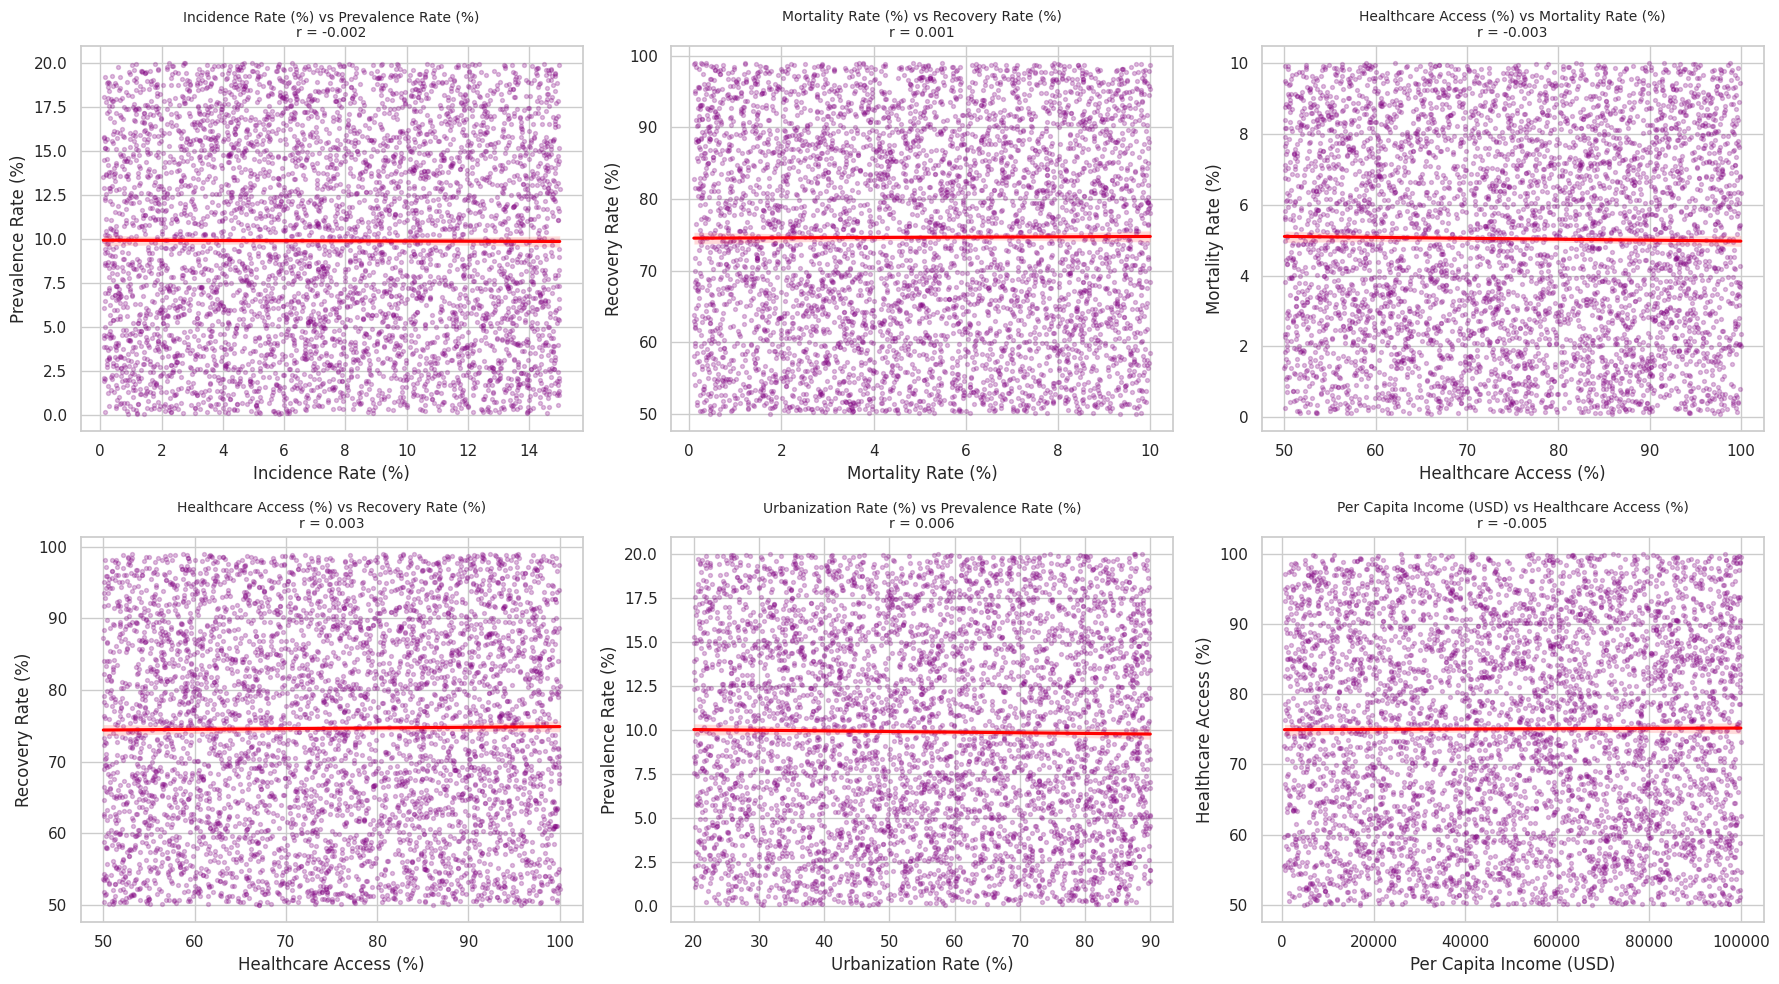

In [19]:
pairs = [("Incidence Rate (%)", "Prevalence Rate (%)"),
         ("Mortality Rate (%)", "Recovery Rate (%)"),
         ("Healthcare Access (%)", "Mortality Rate (%)"),
         ("Healthcare Access (%)", "Recovery Rate (%)"),
         ("Urbanization Rate (%)", "Prevalence Rate (%)"),
         ("Per Capita Income (USD)", "Healthcare Access (%)")]
sample = df.sample(min(5000, len(df)), random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (x, y) in zip(axes.ravel(), pairs):
    sns.regplot(x=x, y=y, data=sample, ax=ax,
                scatter_kws={"alpha": 0.25, "s": 8, "color": "purple"}, line_kws={"color": "red"})
    r = df[x].corr(df[y])
    ax.set_title(f"{x} vs {y}\nr = {r:.3f}", fontsize=10)
plt.tight_layout()
plt.show()

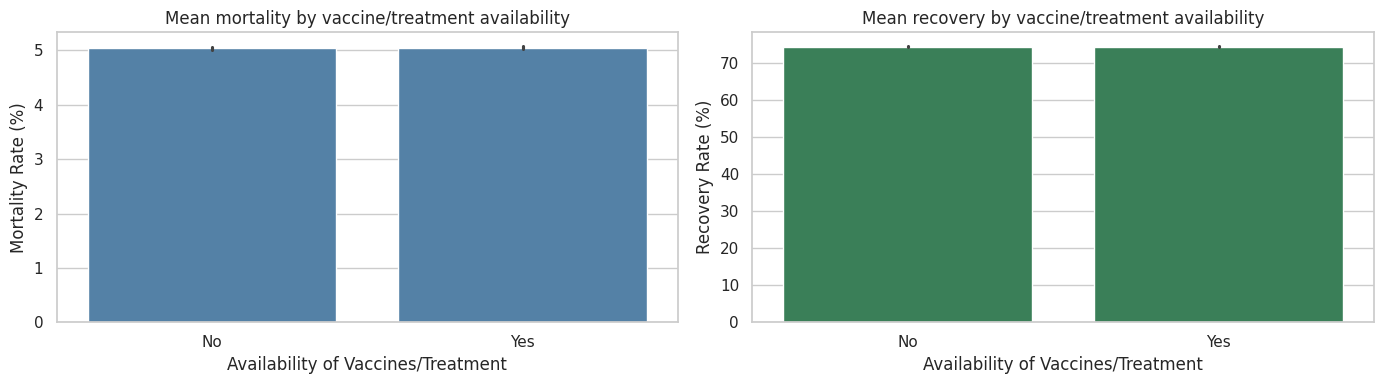

In [20]:
cat_vs = ["Availability of Vaccines/Treatment", "Gender", "Age Group", "Disease Category"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=df, x="Availability of Vaccines/Treatment", y="Mortality Rate (%)", ax=axes[0], color="steelblue")
sns.barplot(data=df, x="Availability of Vaccines/Treatment", y="Recovery Rate (%)", ax=axes[1], color="seagreen")
axes[0].set_title("Mean mortality by vaccine/treatment availability")
axes[1].set_title("Mean recovery by vaccine/treatment availability")
plt.tight_layout()
plt.show()

## 6. Key findings and limitations

**Findings (80,277 records, 22 attributes, 20 countries, 20 diseases, 2023-2024)**
- **Cleaning:** 696 missing cells (under 0.1% per column) were imputed; 0 remain. No duplicate rows were found.
- **Balance:** records per disease range from 3,893 (Tuberculosis) to 4,116 (Cholera), and disease-category shares from 8.91% (Metabolic) to 9.30% (Bacterial). The dataset is almost perfectly balanced, so no disease or category "dominates".
- **Change over time:** average mortality rate moved from 5.044% (2023) to 5.050% (2024), a change of 0.13%. Prevalence, healthcare access, income and education changed by less than 0.3% each. These changes are too small to call a trend, and there are only two years.
- **Distributions:** every numeric column is symmetric (skewness between -0.01 and +0.01) and roughly flat across its range, with means near the midpoint of the range (e.g. DALYs 1-5000 with mean about 2,500; mortality 0.1-10% with mean about 5.05%).
- **Relationships:** the strongest correlation between any two numeric columns is |r| = 0.009, which is essentially zero. Healthcare access, doctors, hospital beds, income and education show no measurable relationship with mortality or recovery. Mean mortality (5.044% vs 5.049%) and recovery (74.56% vs 74.52%) are also nearly identical whether vaccines/treatment are available or not.
- **Country level:** average mortality ranges only from 4.93% (USA) to 5.11% (South Korea), a spread that is within what random variation would produce.

**Interpretation and limitations**
- The flat distributions, the even category counts and the near-zero correlations strongly suggest the data was **randomly generated (synthetic)**. In real health data, income, healthcare access and mortality would be clearly related. This is why the analysis finds no real-world patterns, and conclusions here should not be read as findings about actual global health.
- Only two years of data, so no long-term trends can be claimed.
- Missing values were imputed with mean/median/mode, which slightly reduces variance. The amount missing is very small, so the effect is minimal.
- Correlation does not imply causation.